Arquivo de dados: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17_CATEGORY.feather
Número de linhas: 118,036
Número de variáveis: 39
PDF de saída: /Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/03_Analise_estatistica/01_Frequencias_PENSE2024.pdf
Rótulos carregados da coluna 'Nova codificacao' para 39 variáveis.


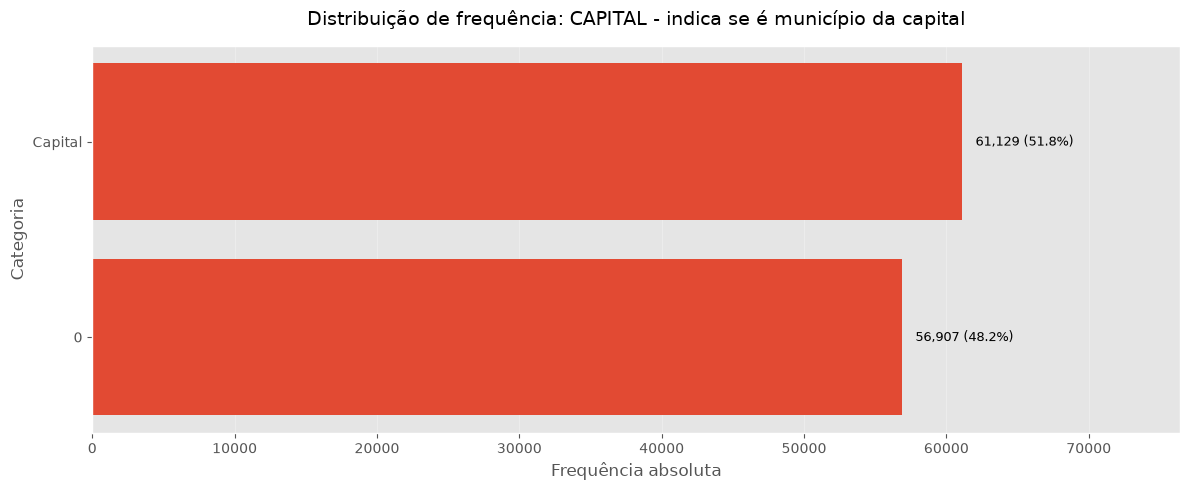

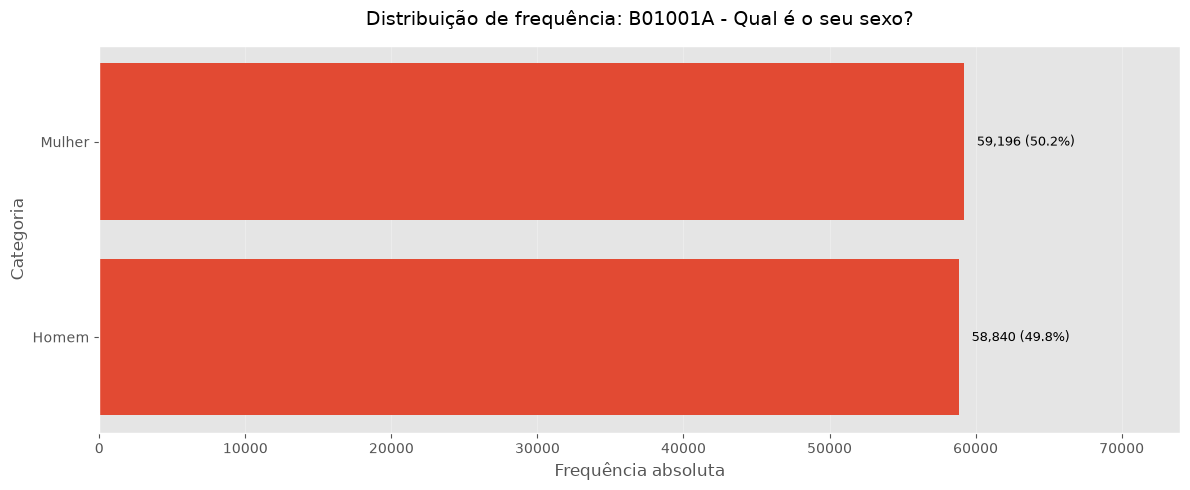

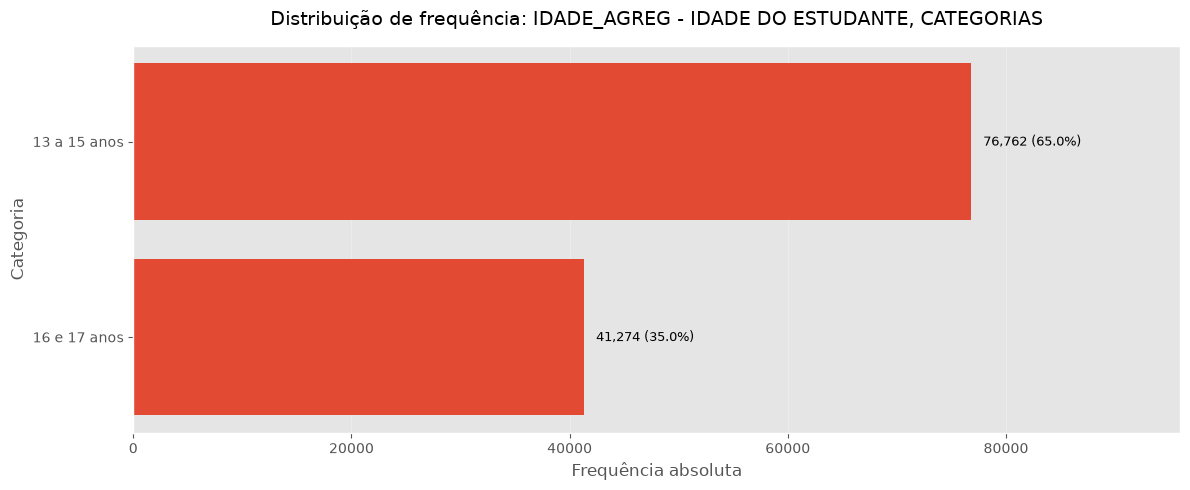

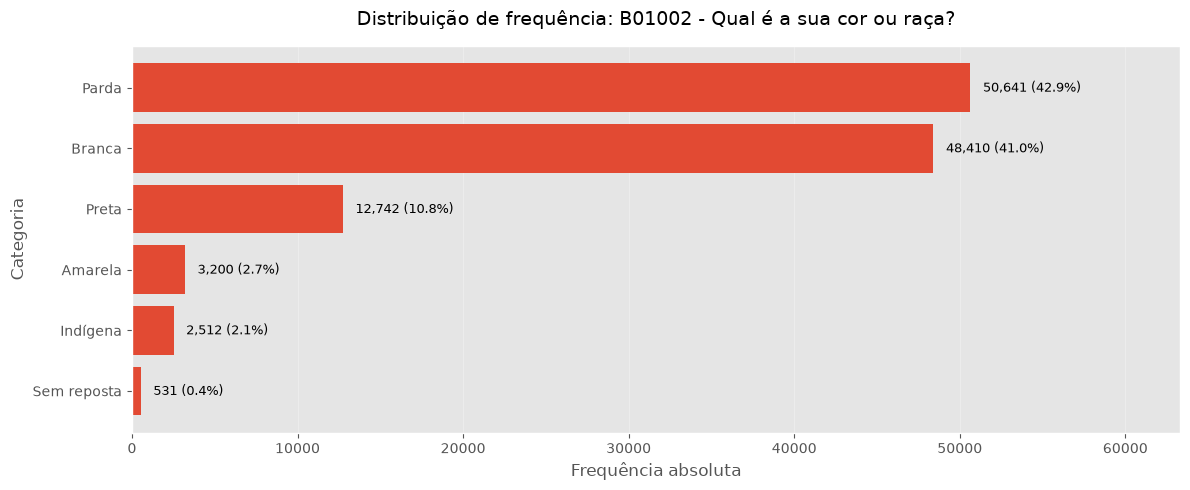

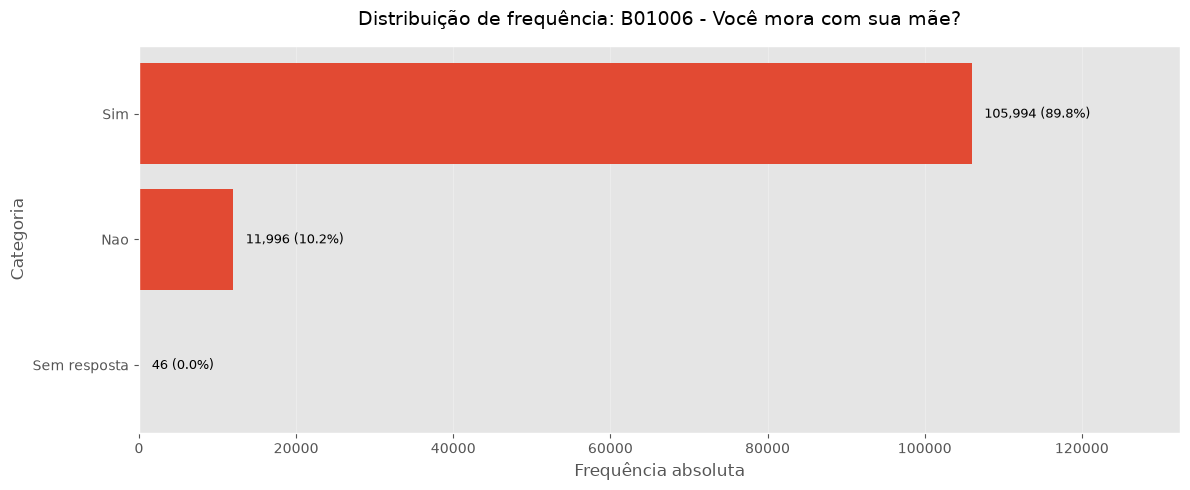

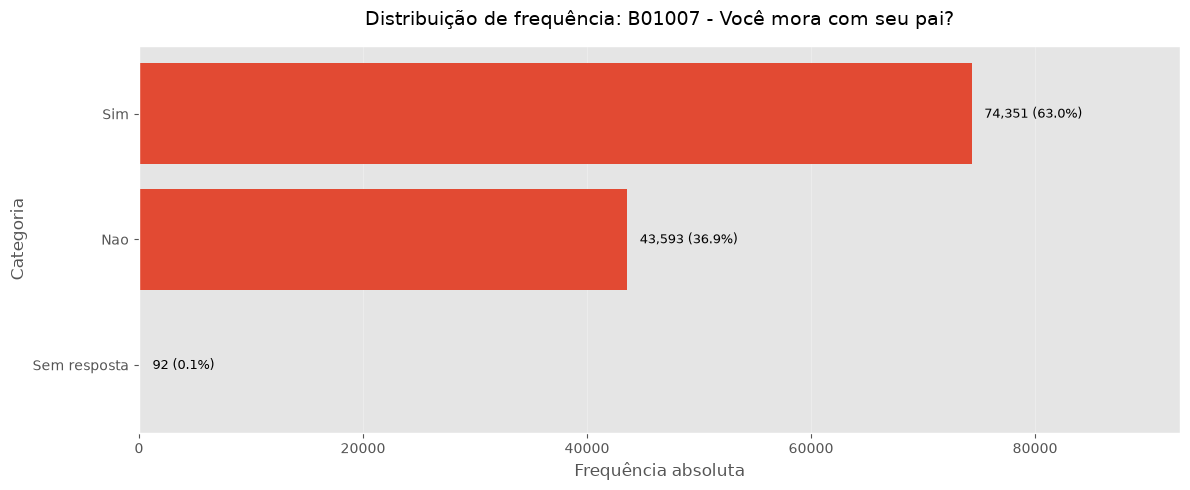

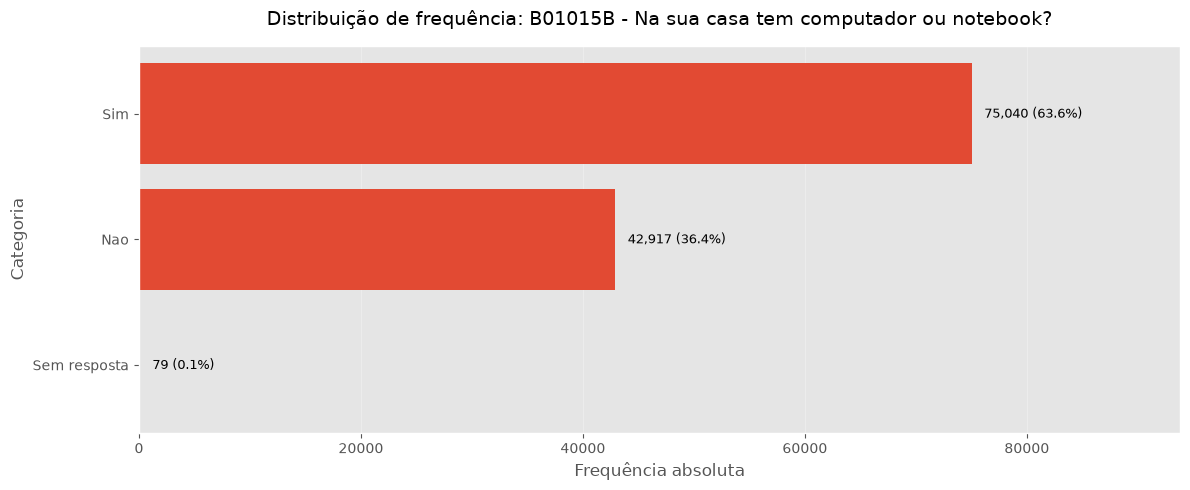

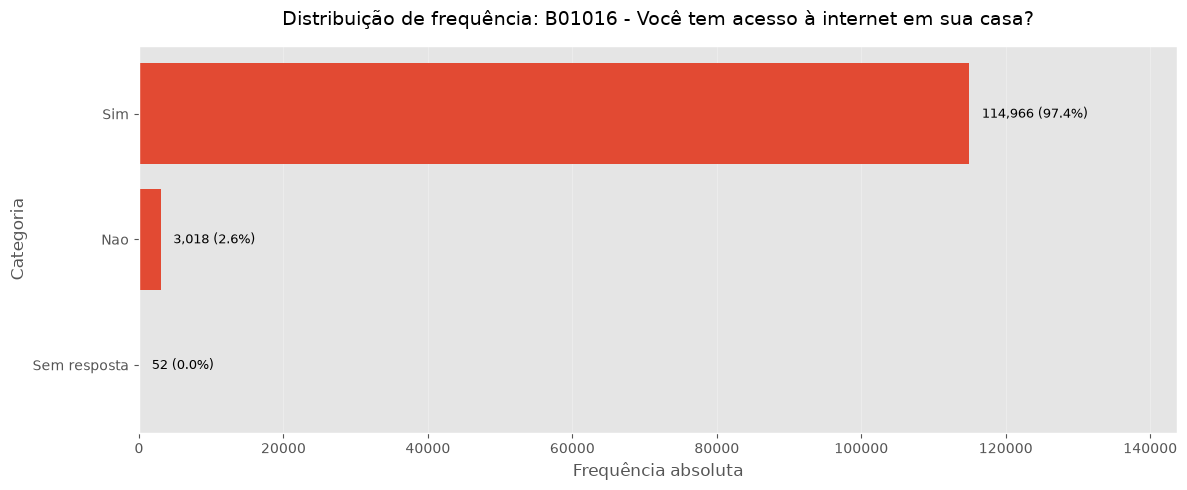

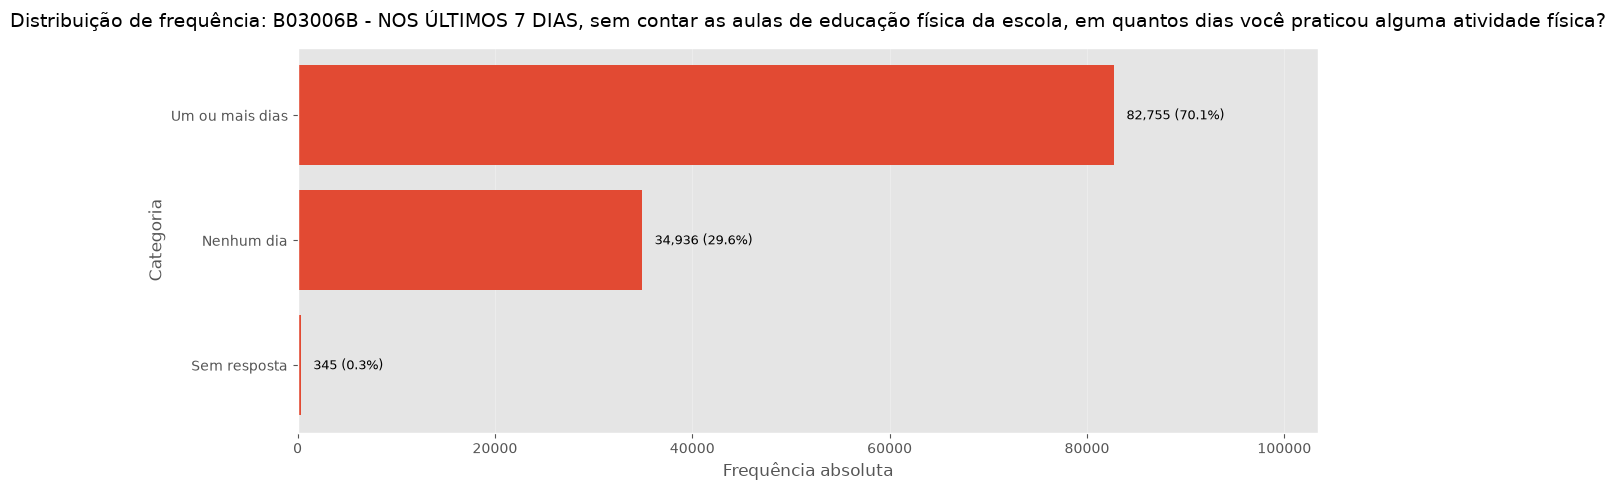

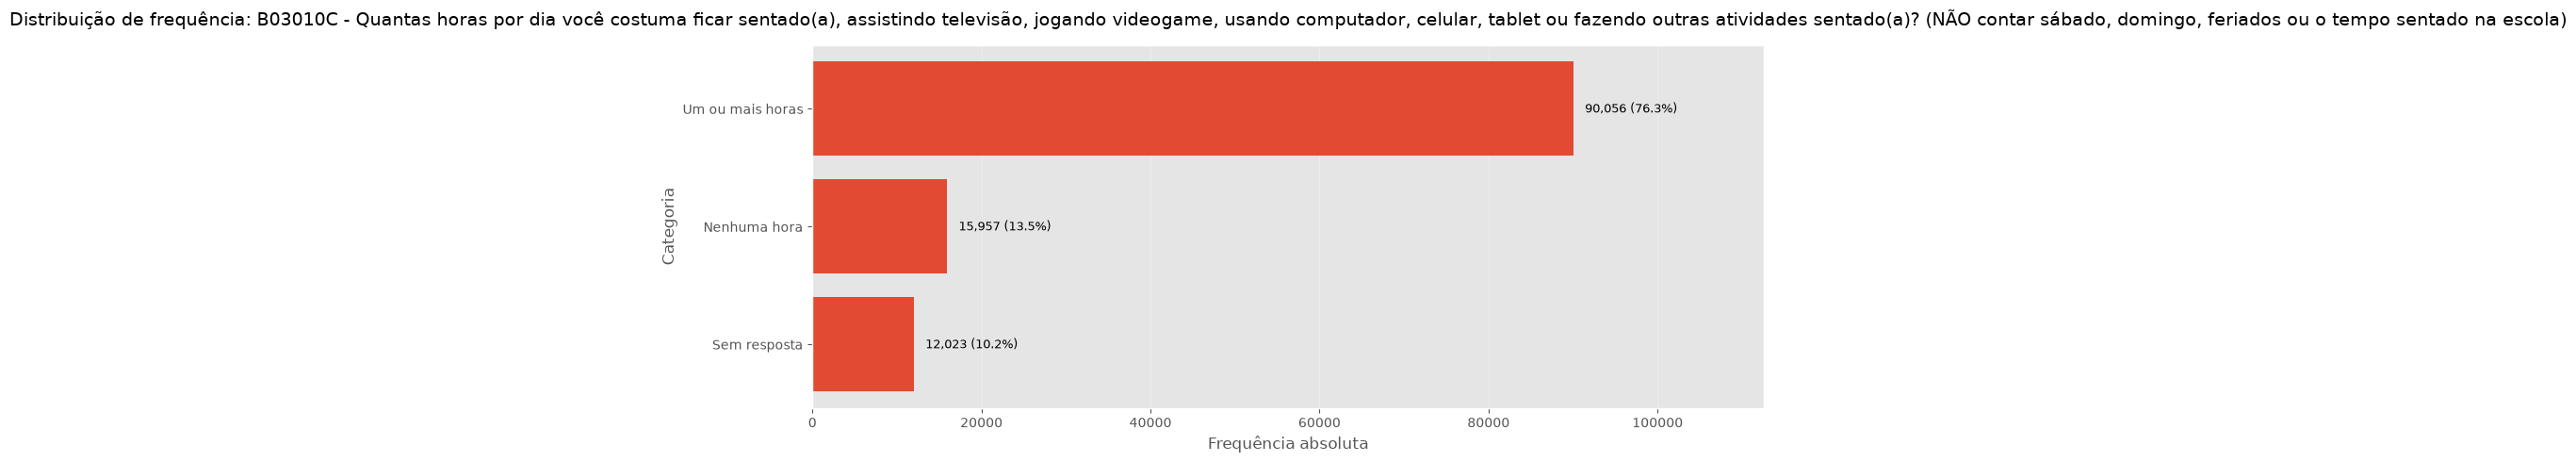

Gráficos processados: 10/39


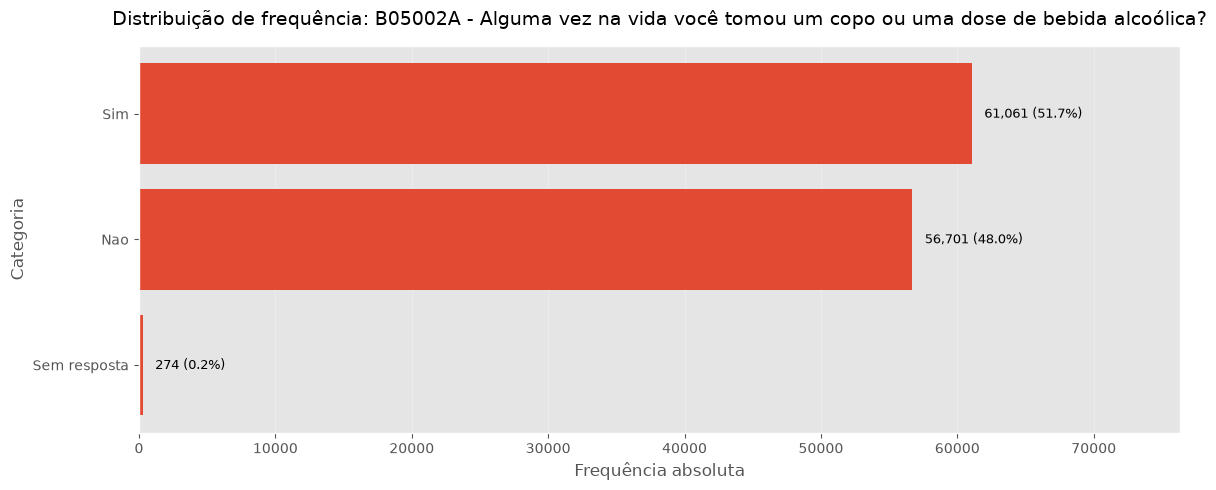

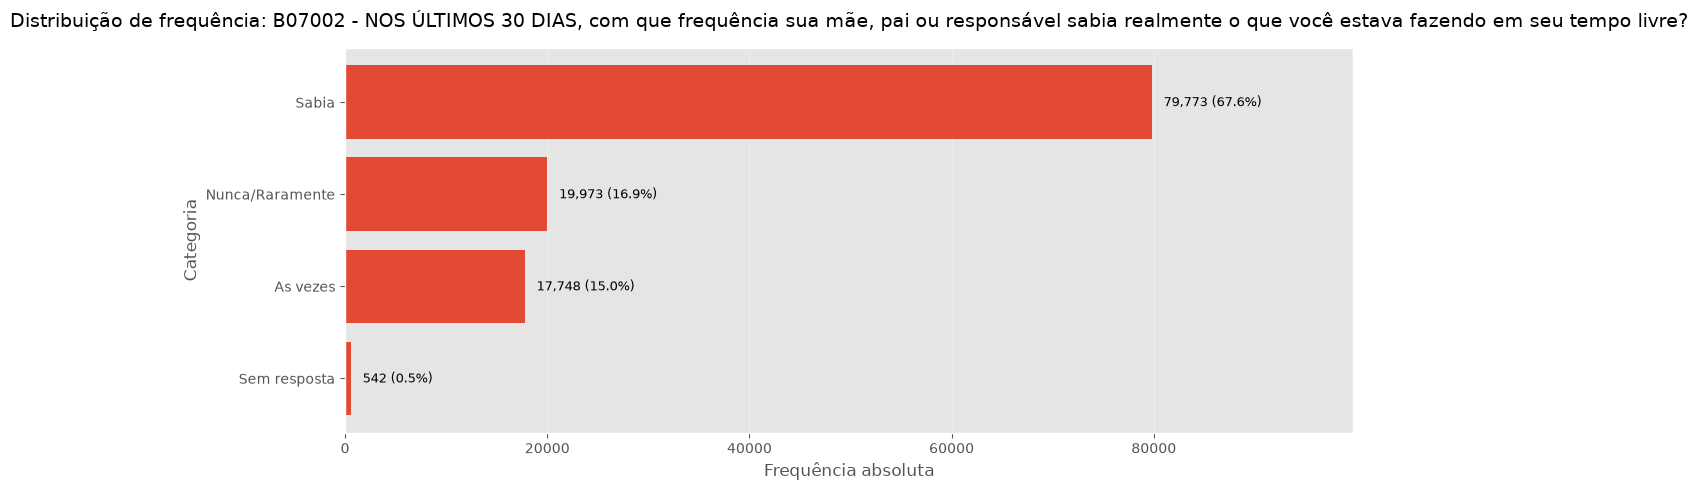

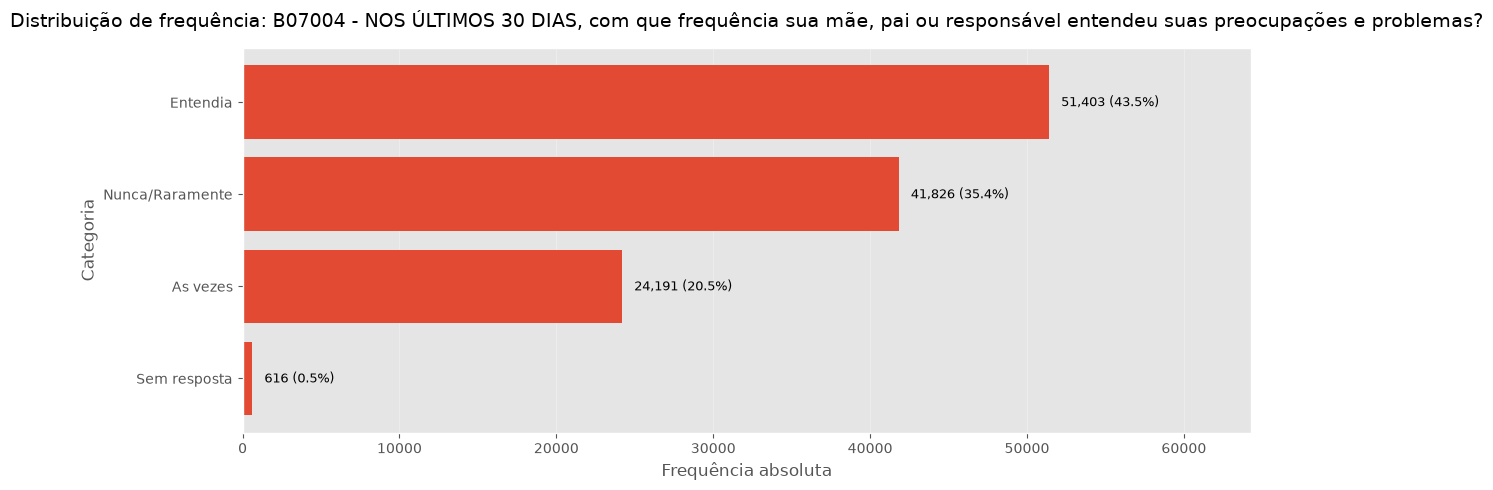

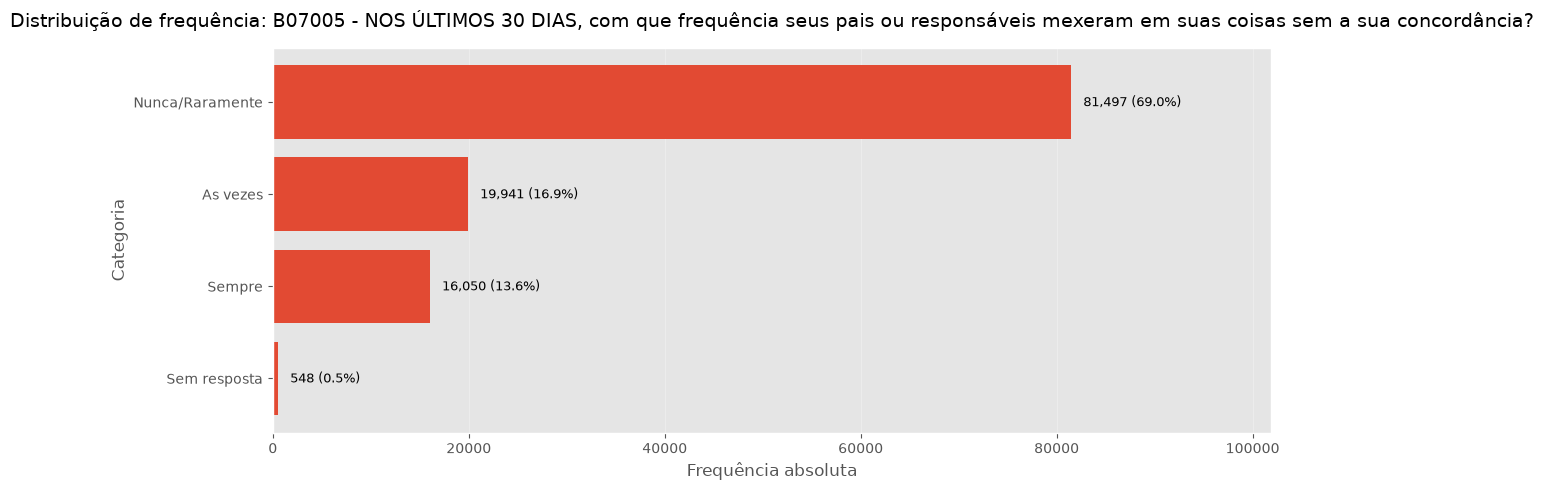

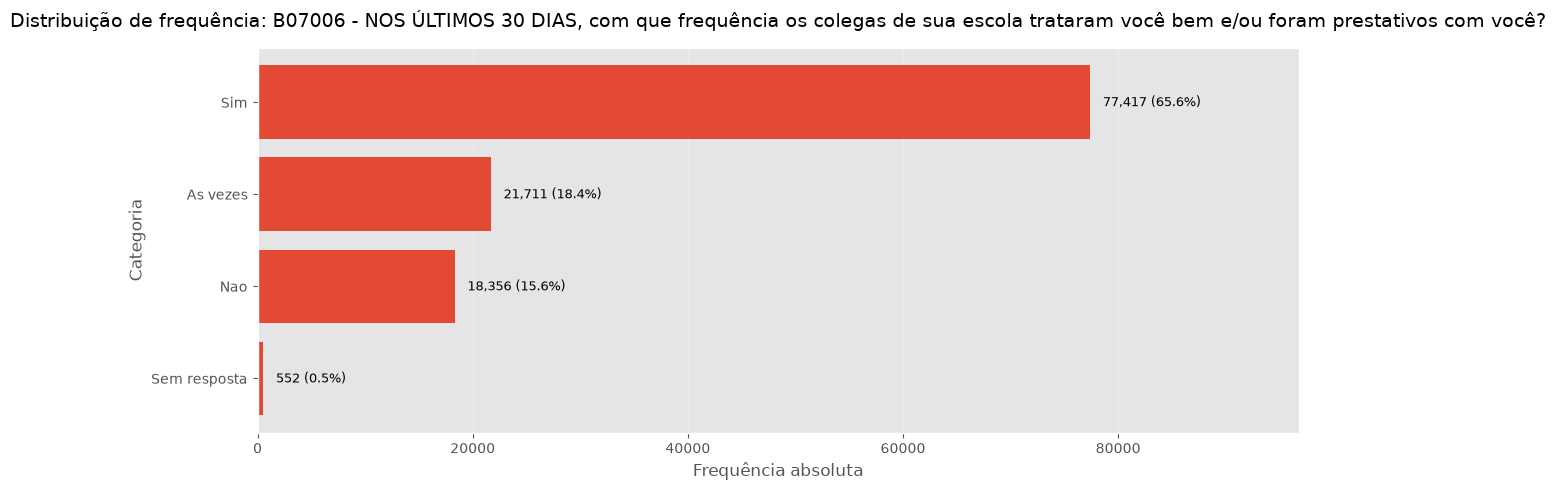

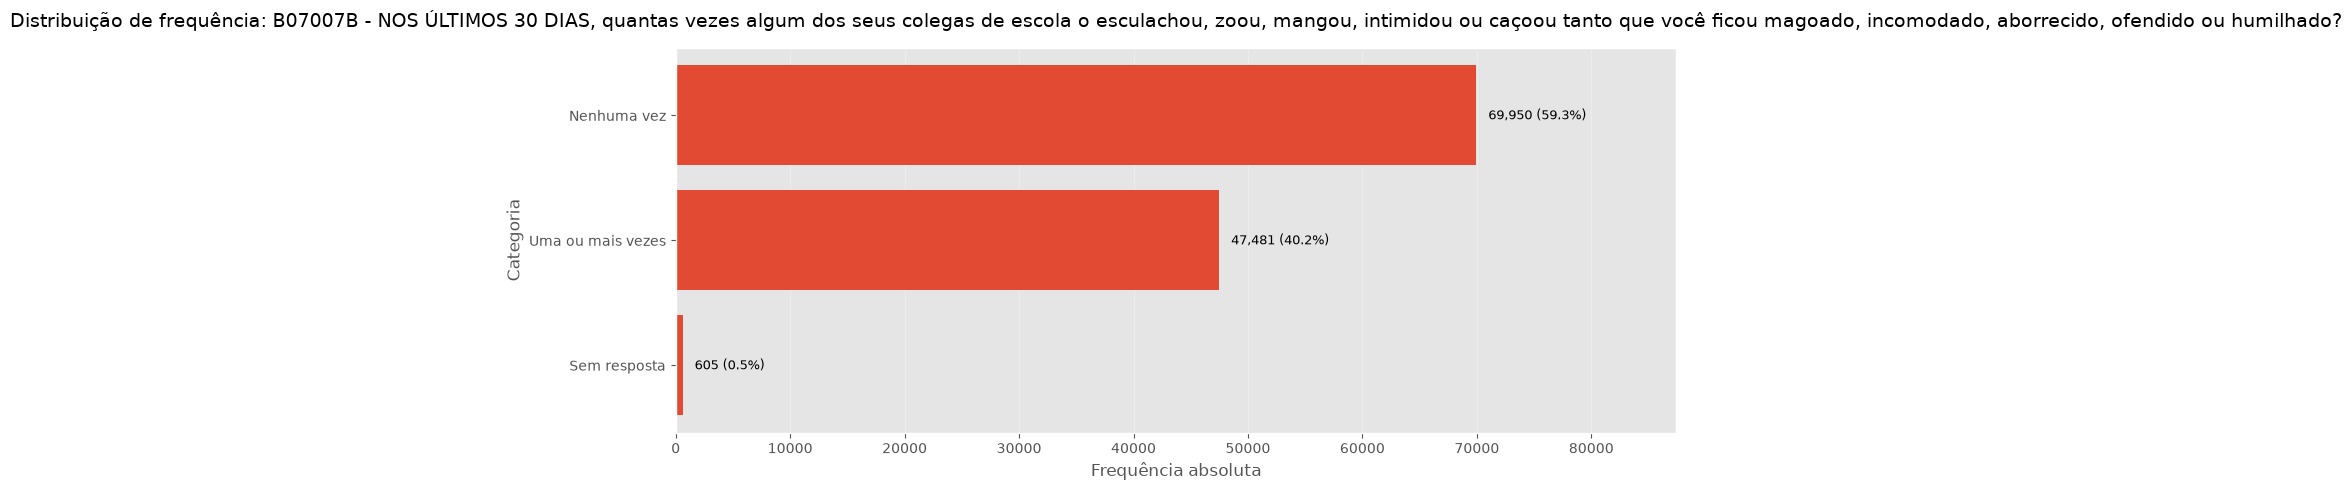

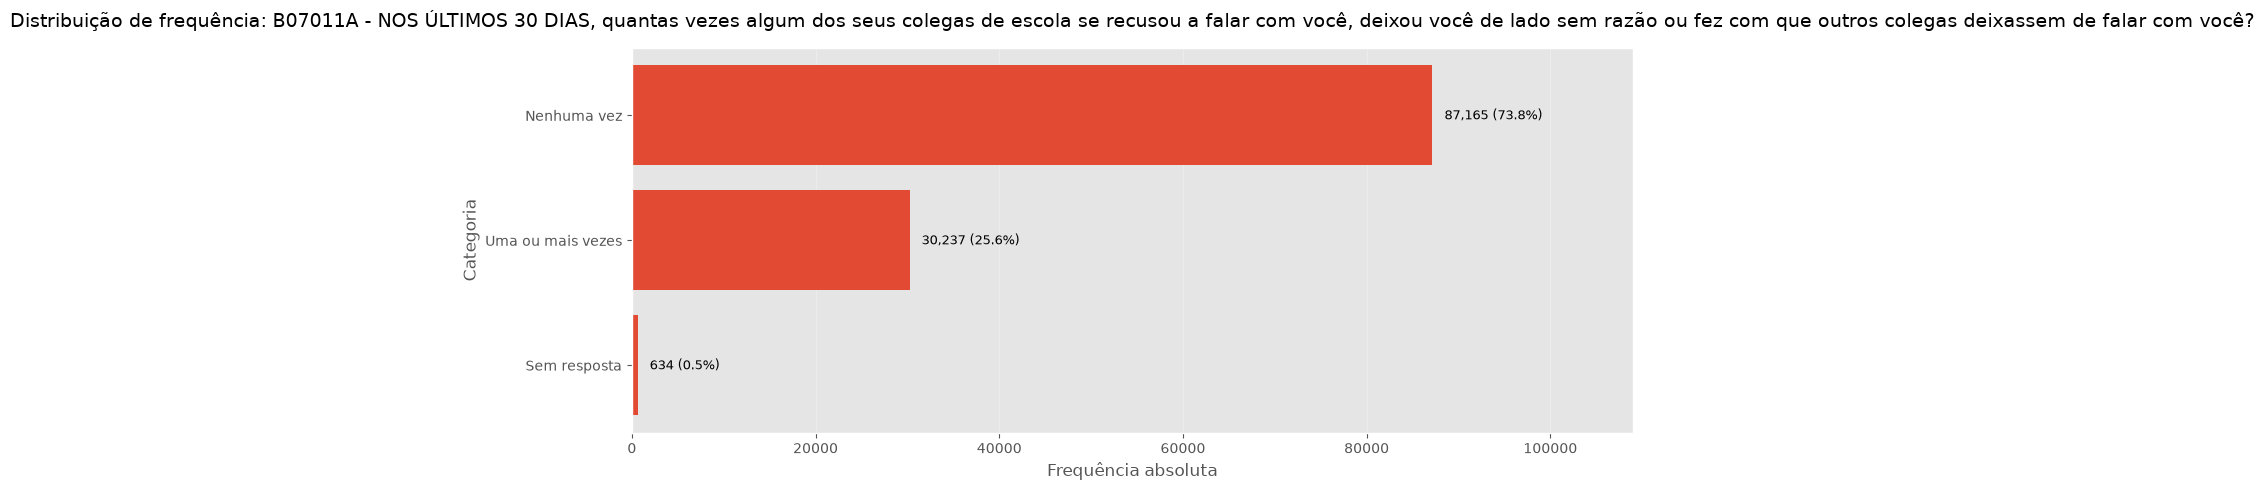

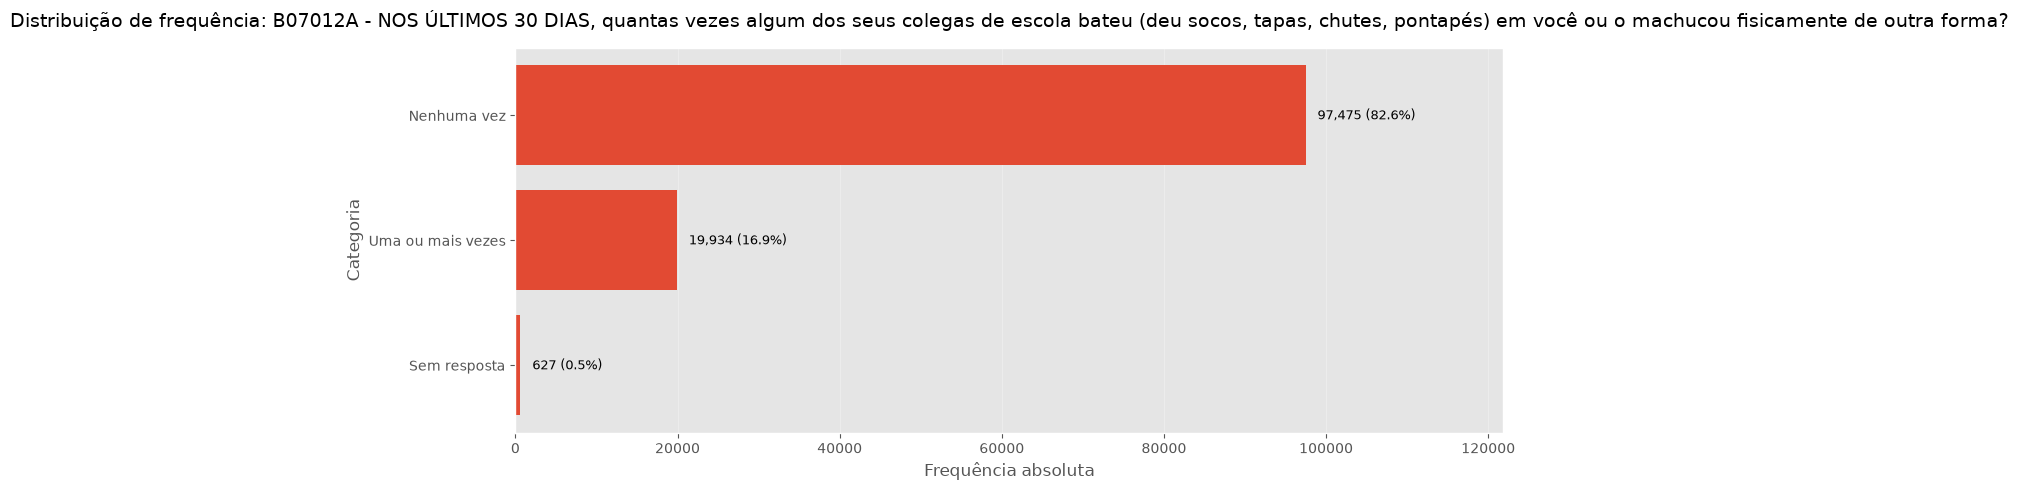

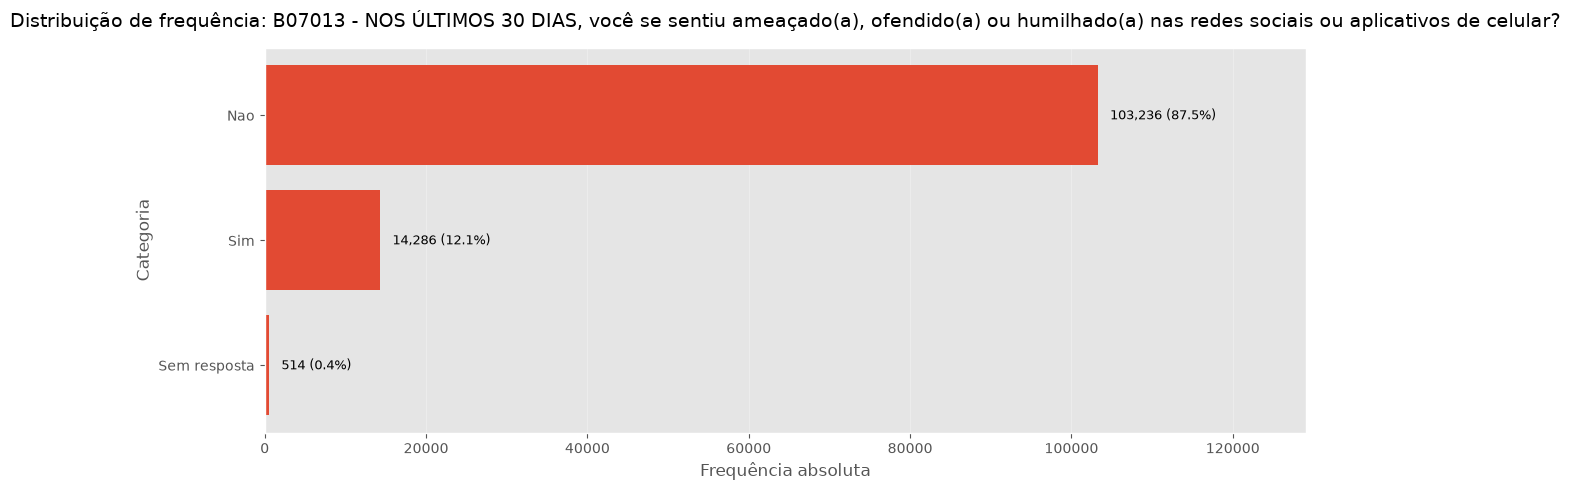

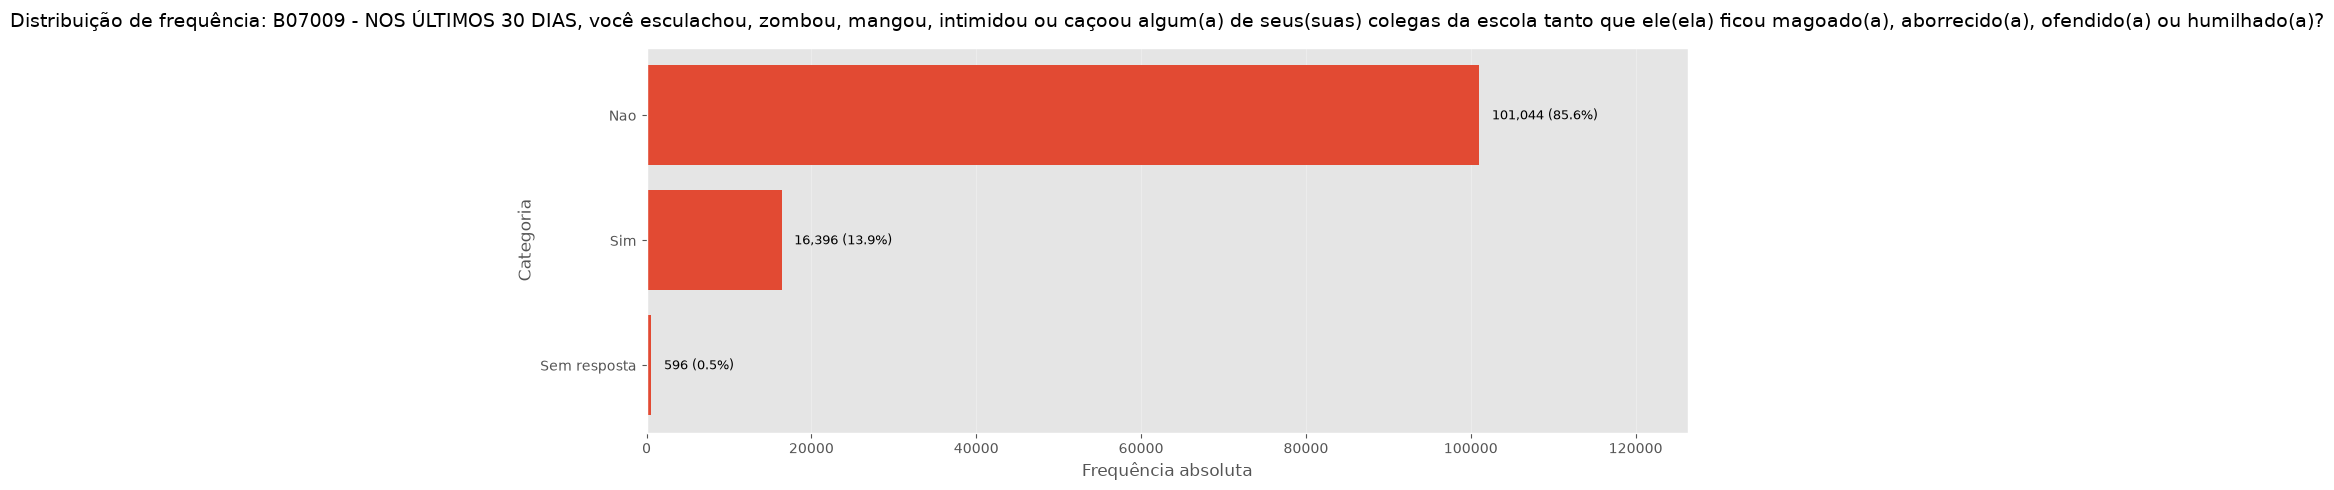

Gráficos processados: 20/39


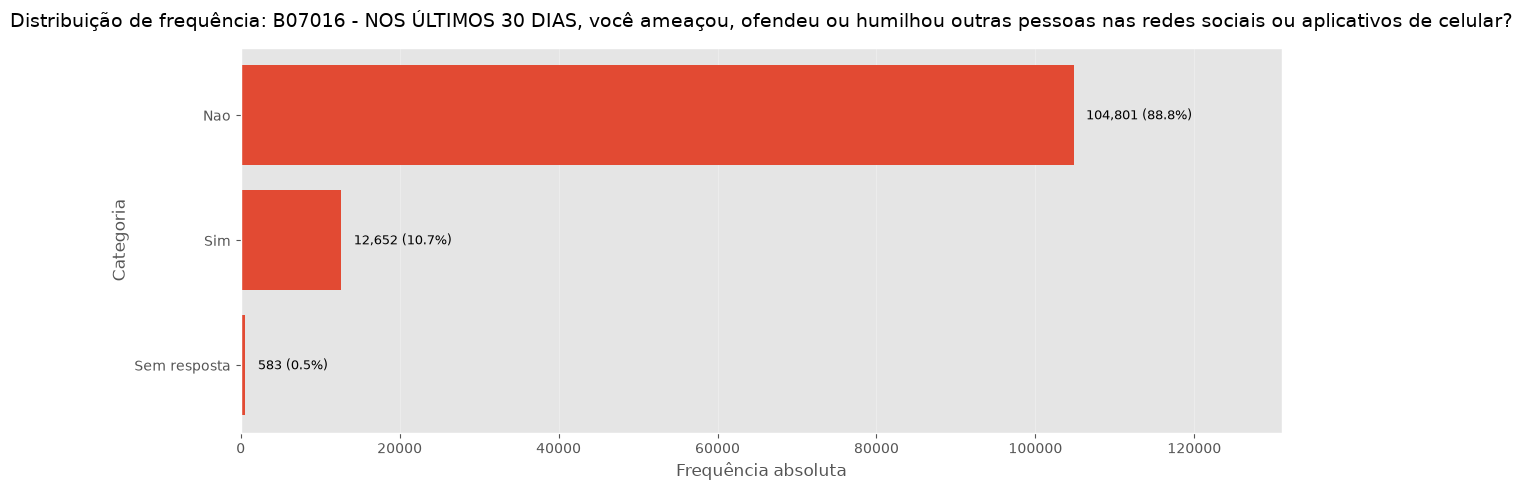

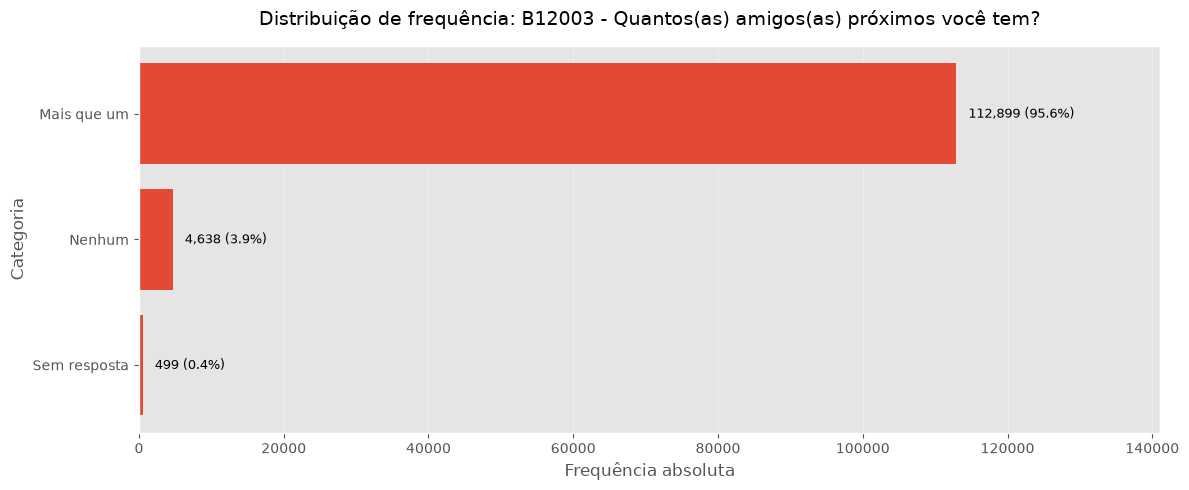

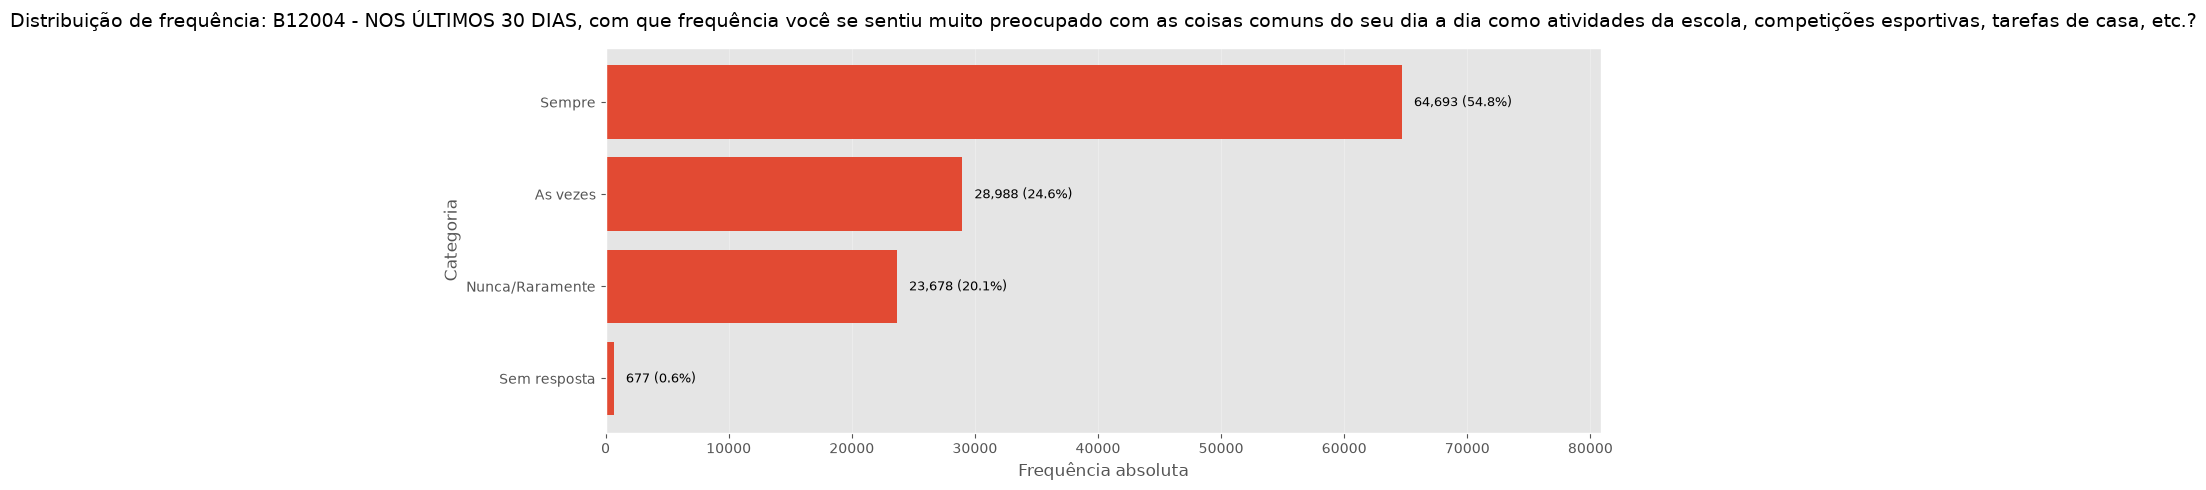

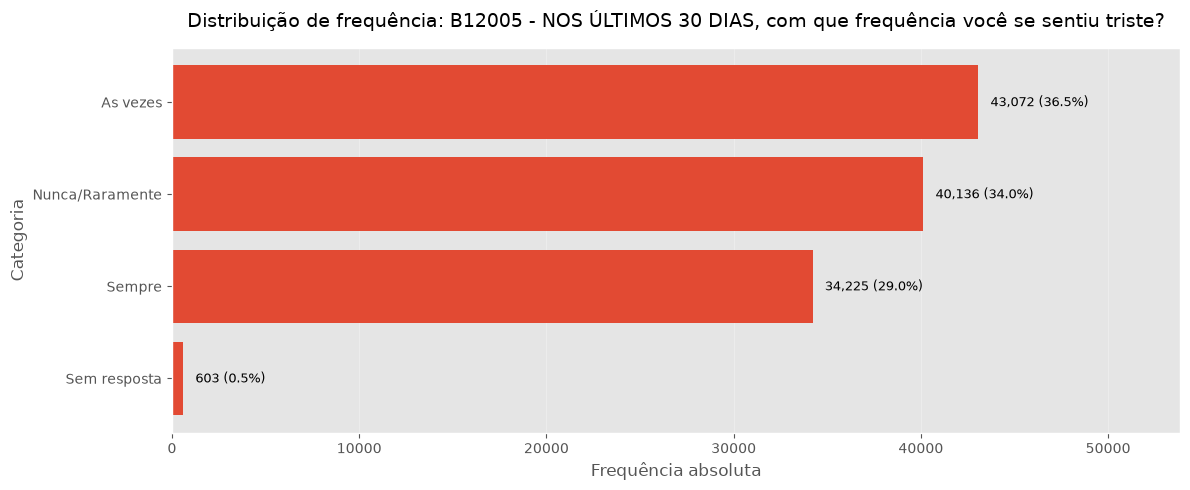

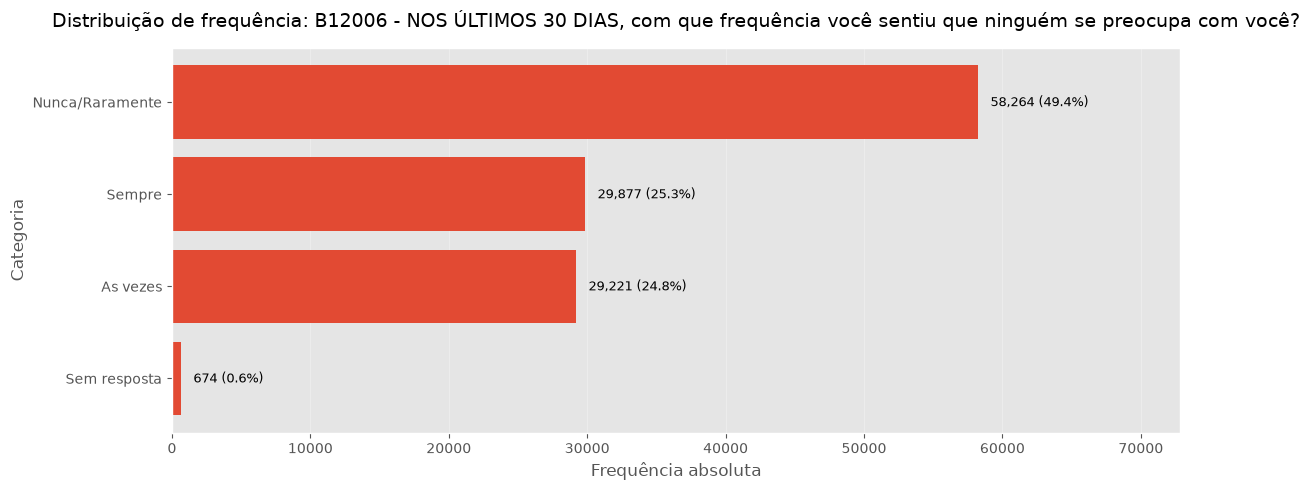

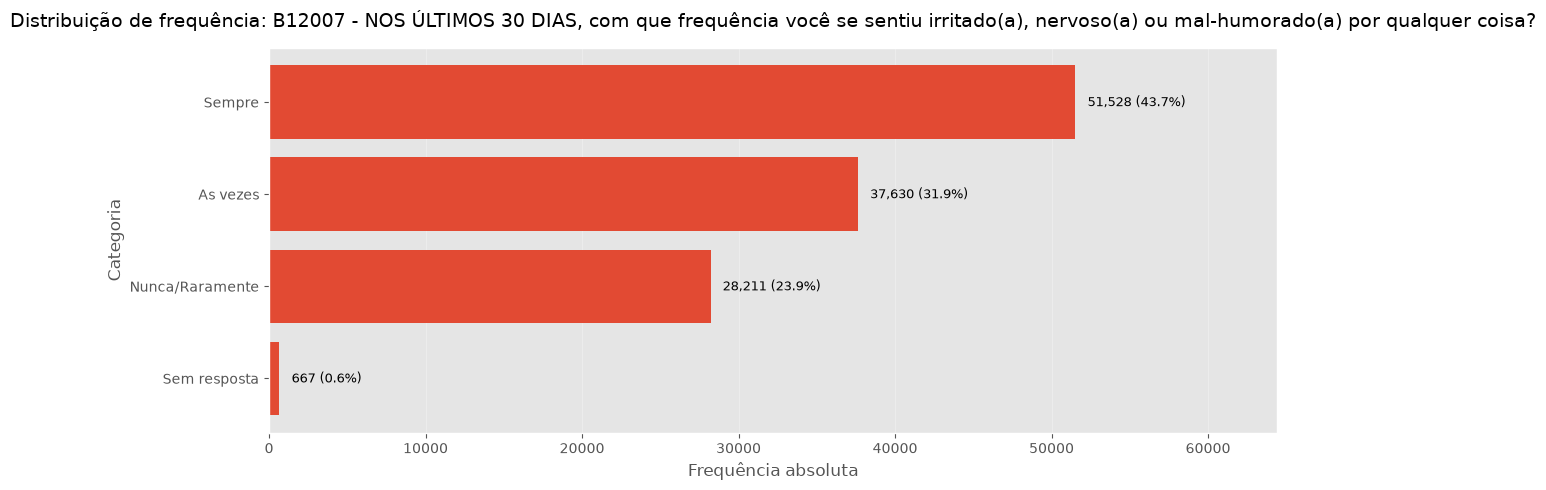

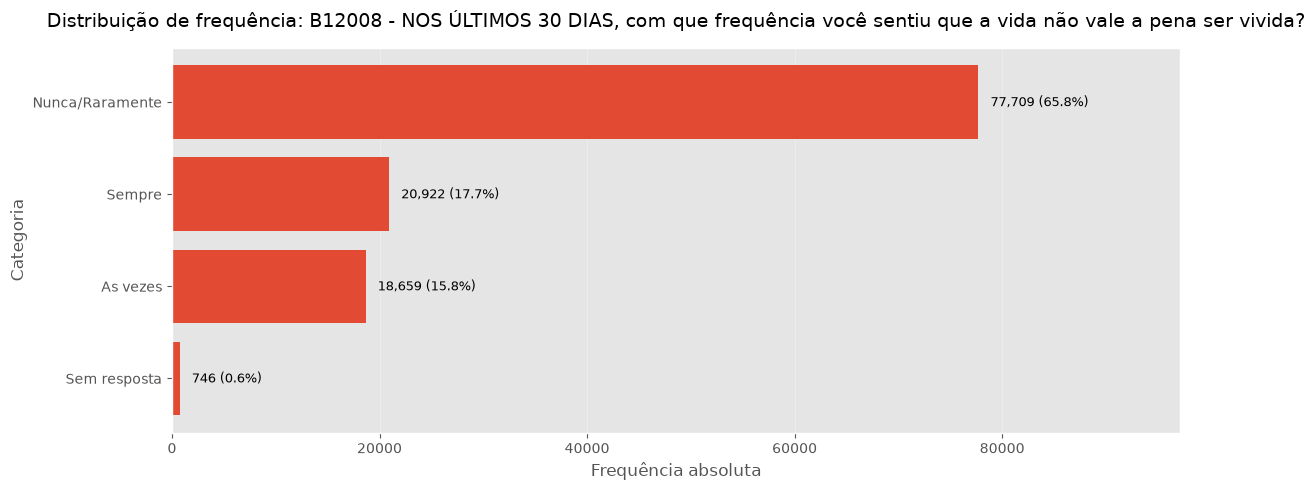

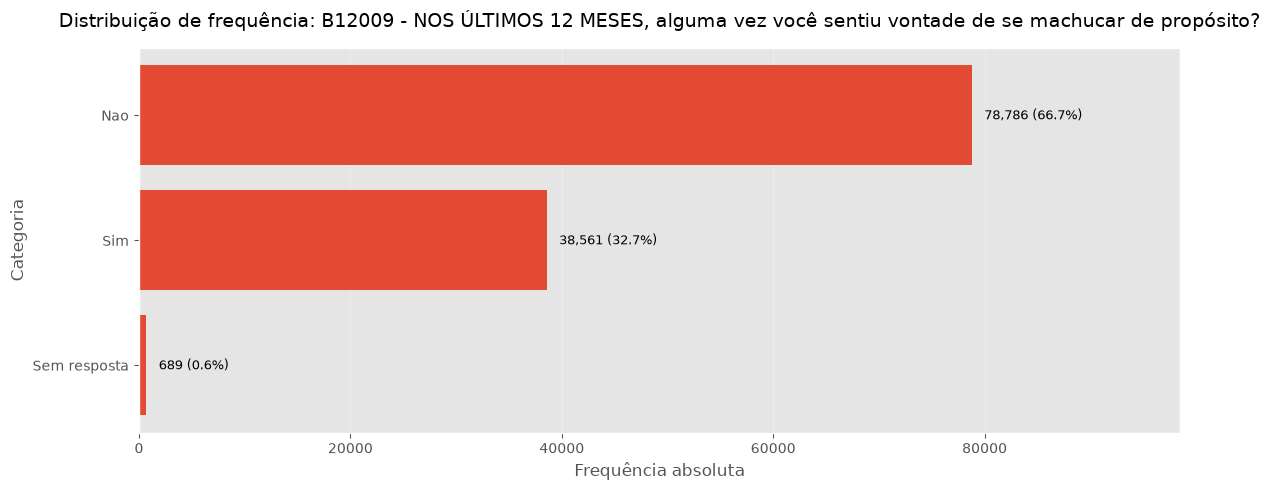

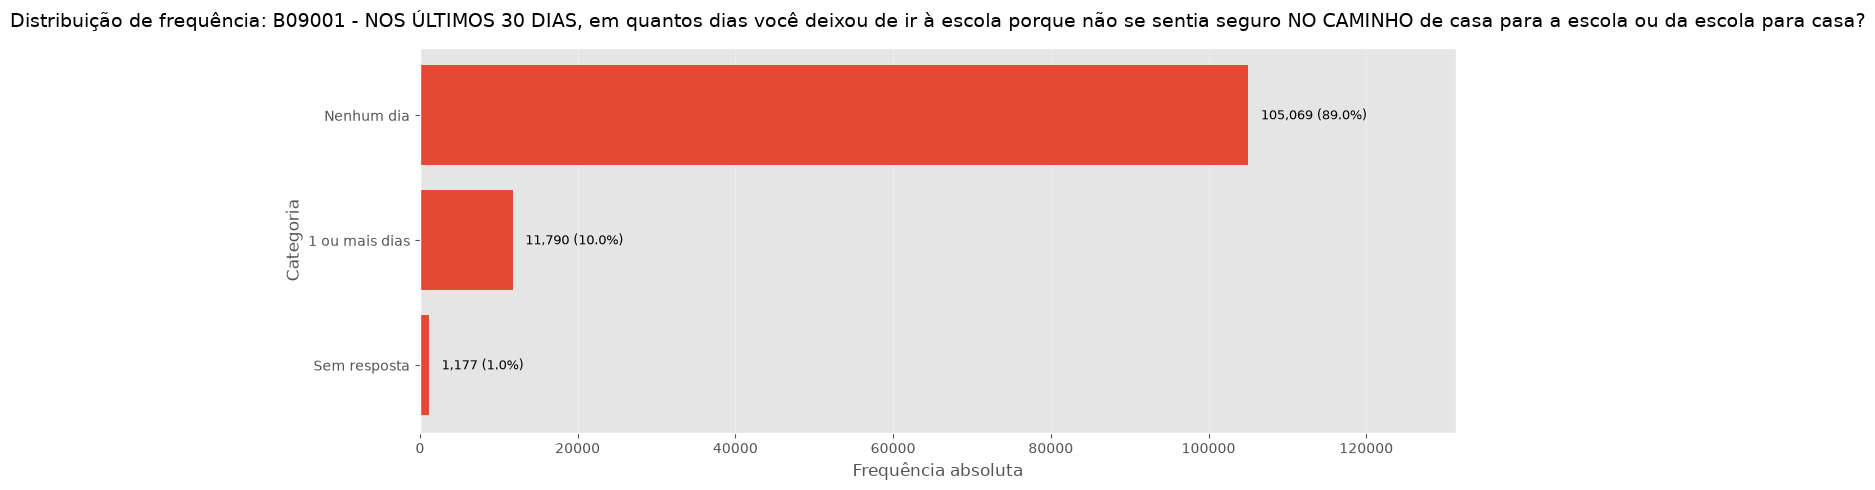

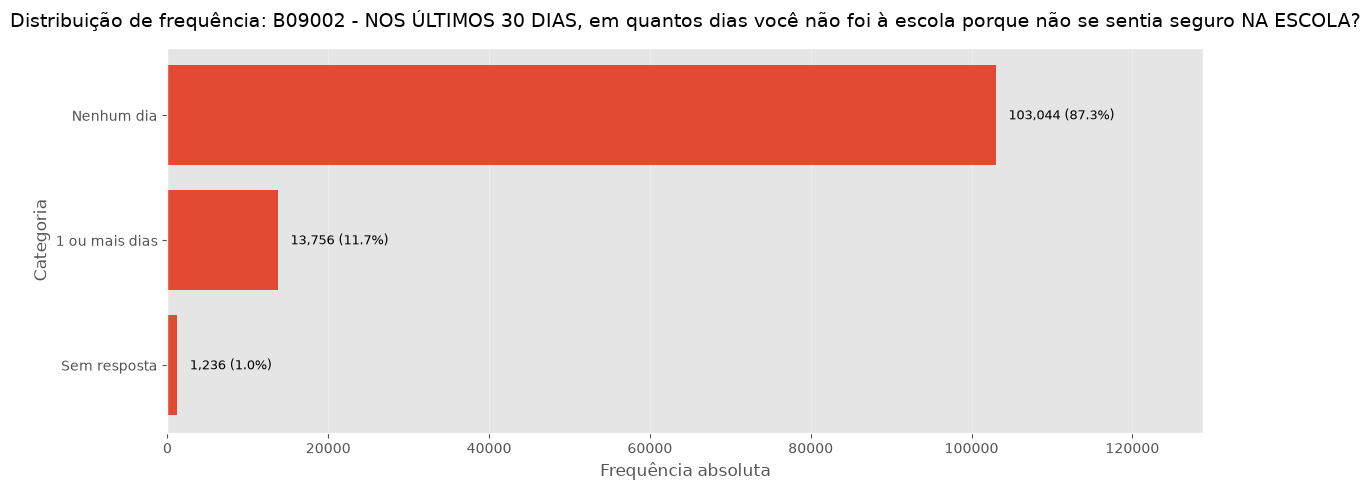

Gráficos processados: 30/39


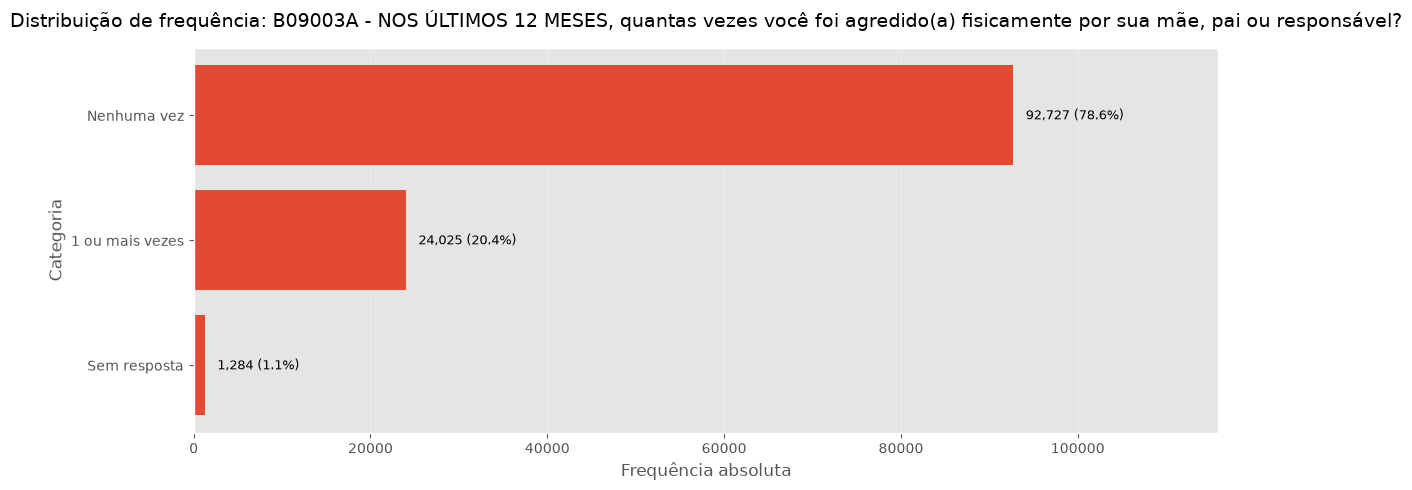

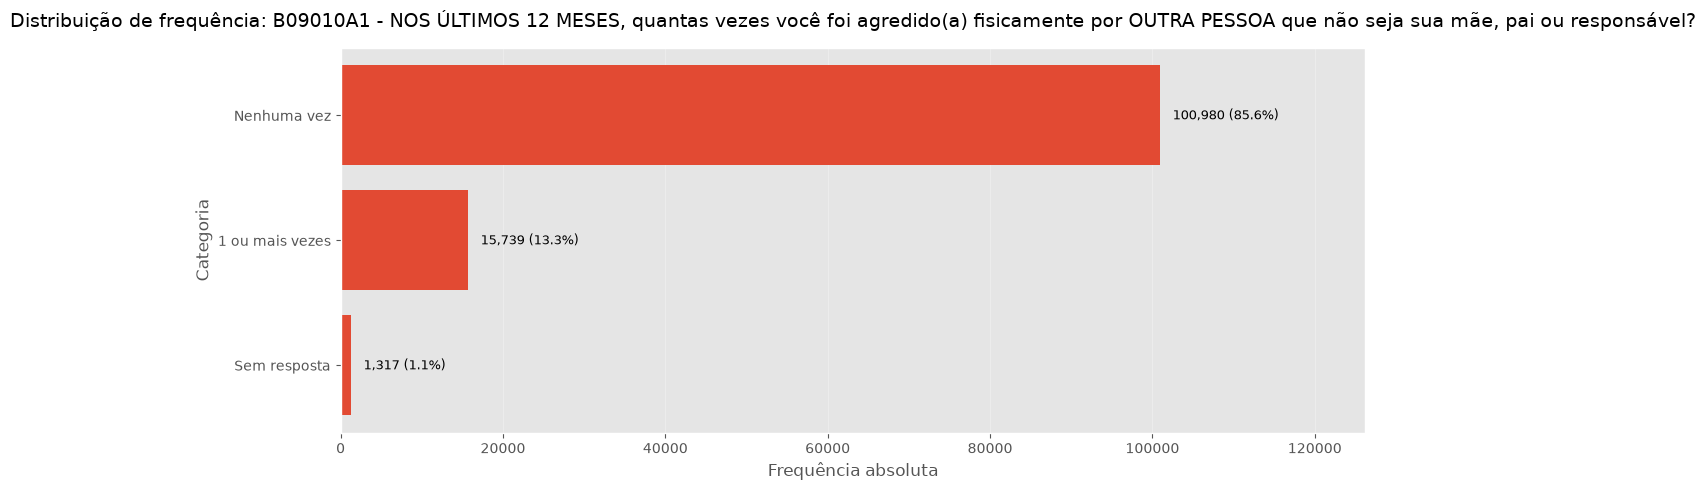

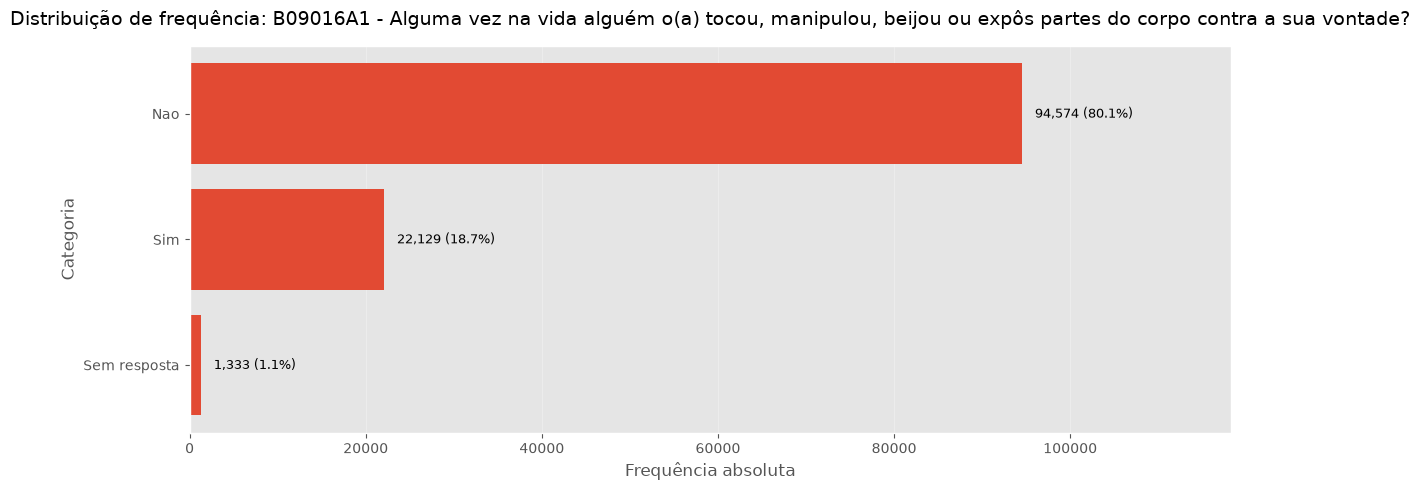

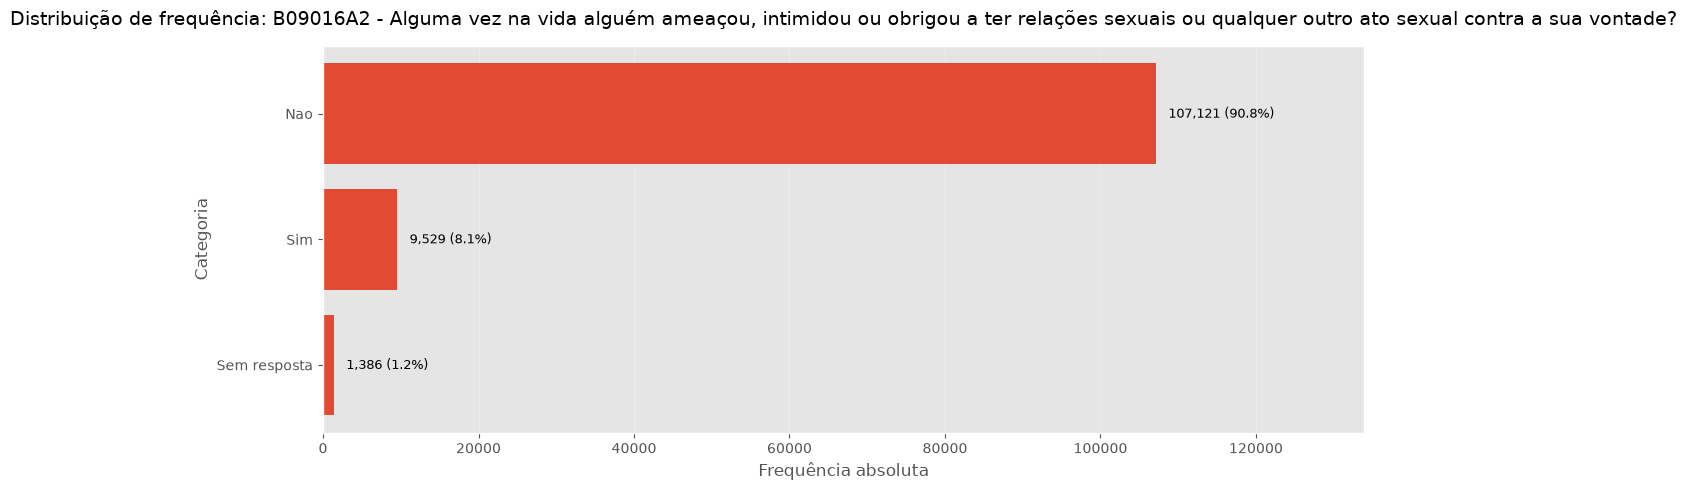

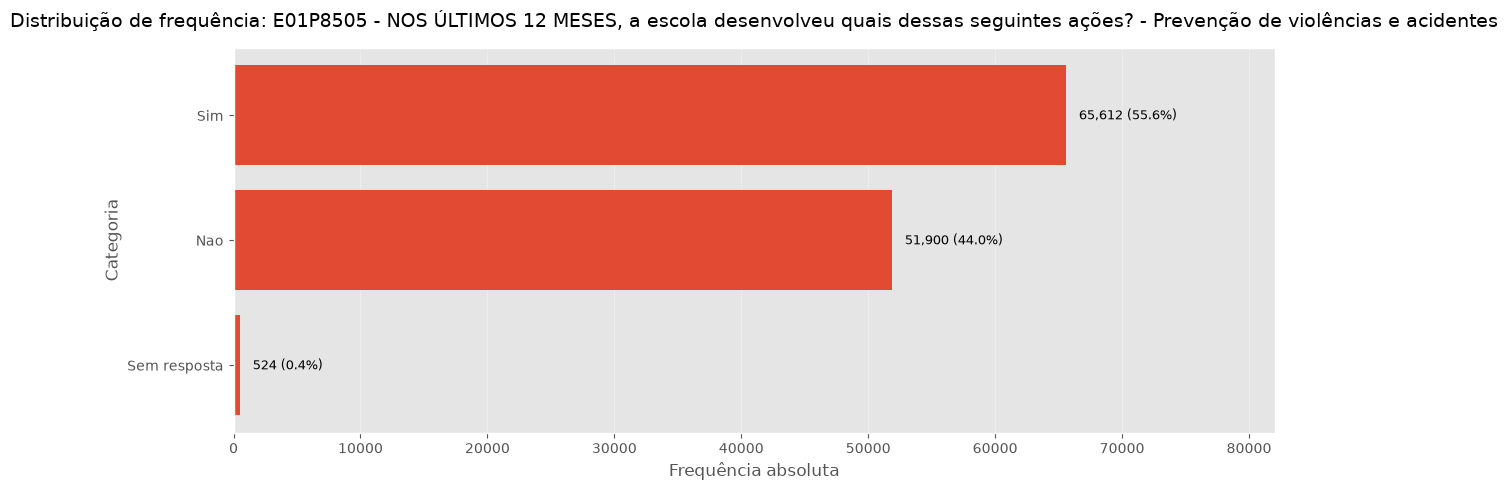

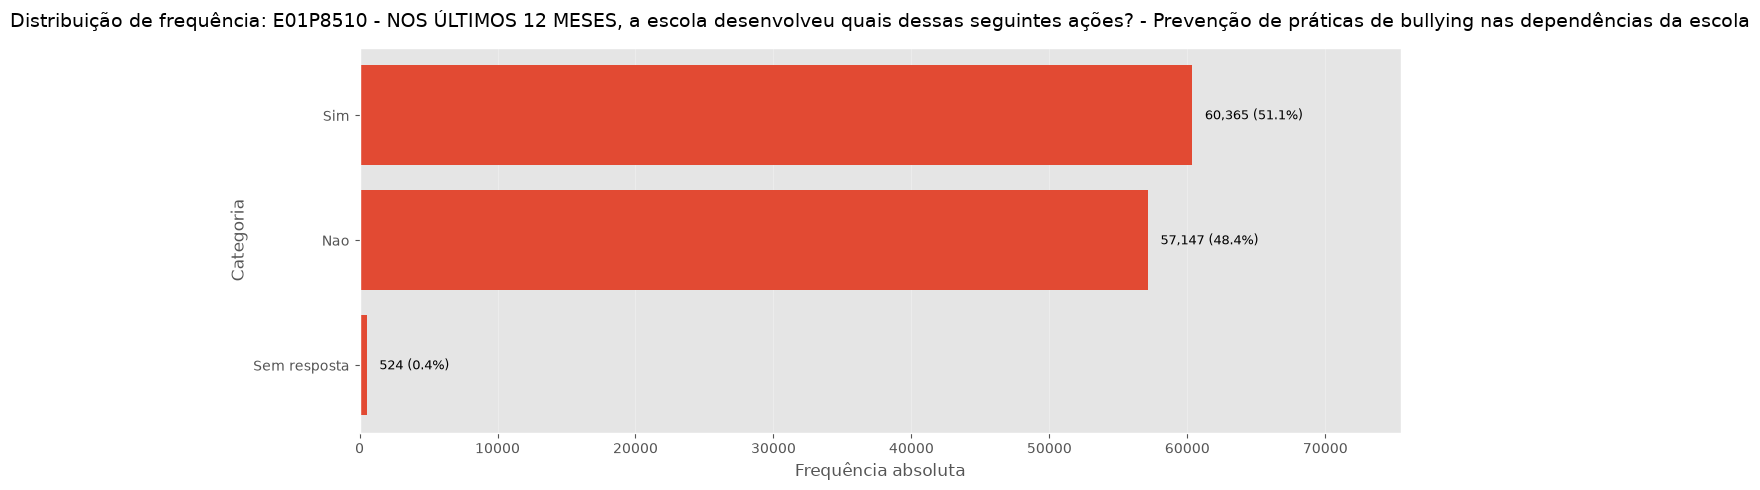

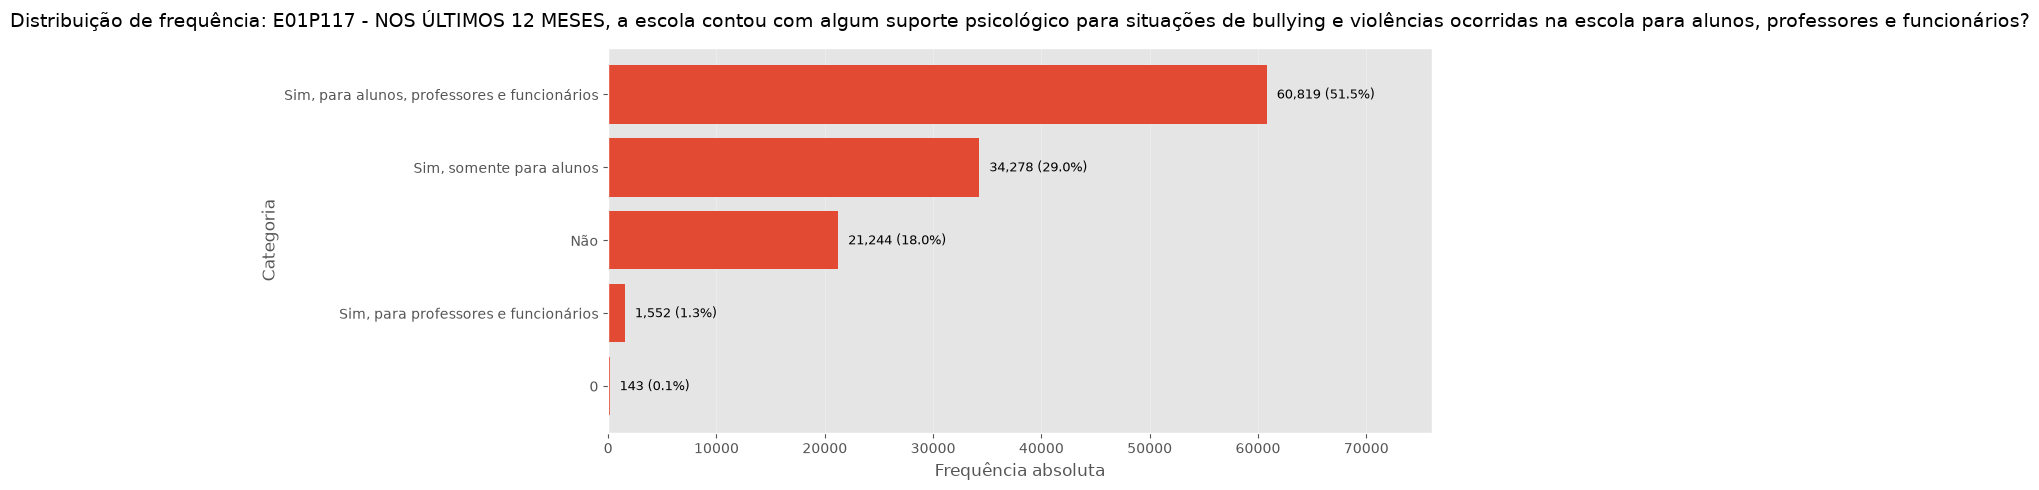

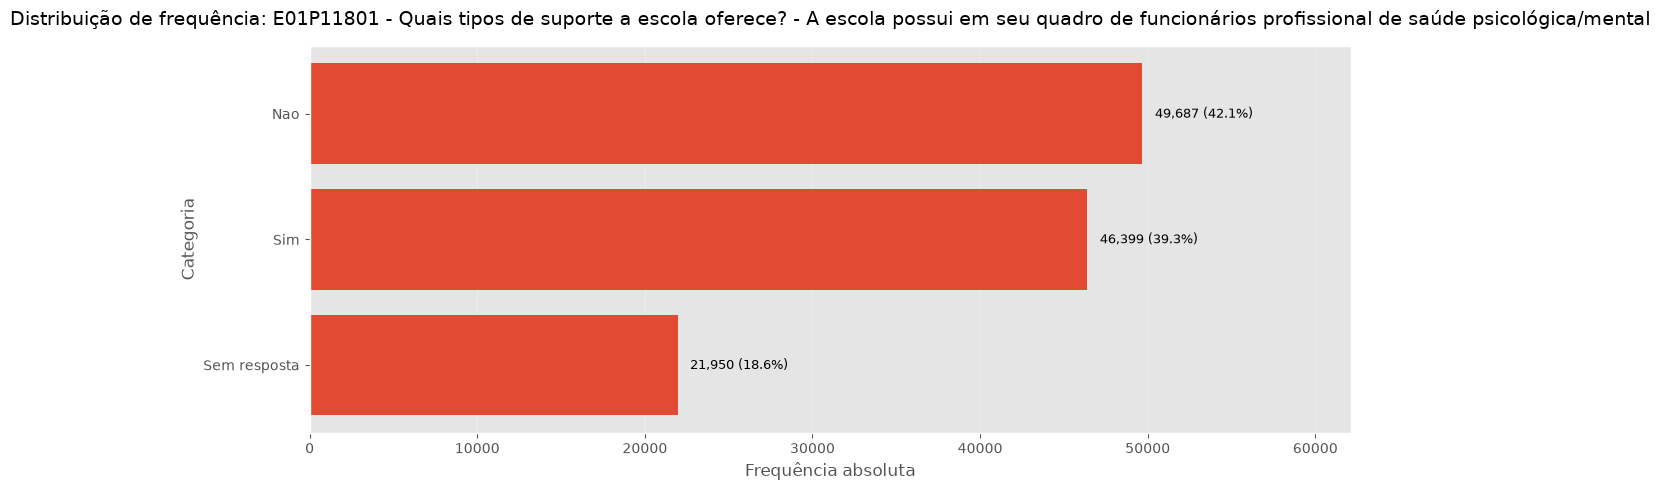

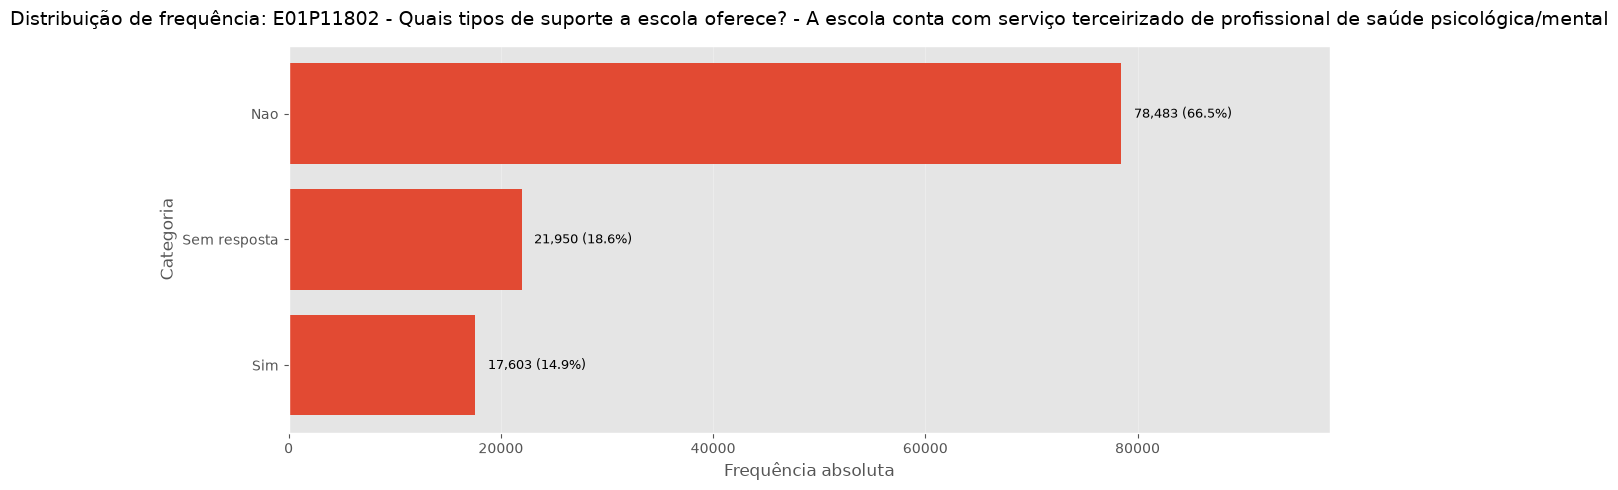

Gráficos processados: 39/39

Processo concluído!
Todos os 39 gráficos foram exibidos no notebook.


In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

# Planilha correta: contém a coluna "Nova codificacao".
arquivo_dicionario = Path(
    "/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/"
    "01_Colunas_recomendadas_pense_2024_final.xlsx"
)

# Salvar o PDF na pasta de trabalho atual do Jupyter Notebook
pasta_saida = Path.cwd()
pasta_saida.mkdir(parents=True, exist_ok=True)

# Nome do único PDF (começa com 01_)
arquivo_pdf = pasta_saida / "01_Frequencias_PENSE2024.pdf"

# Aparência dos gráficos
plt.style.use("ggplot")

# Número máximo de categorias mostradas por gráfico.
# Use None para mostrar todas as categorias.
max_categorias = 30

# ============================================================
# 2. LER A BASE DE DADOS (FEATHER)
# ============================================================

# Leitura alterada de read_parquet para read_feather
df = pd.read_feather(arquivo)

print(f"Arquivo de dados: {arquivo}")
print(f"Número de linhas: {len(df):,}")
print(f"Número de variáveis: {len(df.columns)}")
print(f"PDF de saída: {arquivo_pdf}")

# Garantir que todas as variáveis sejam categóricas
df = df.astype("category")


# ============================================================
# 3. CARREGAR OS RÓTULOS DA COLUNA "Nova codificacao"
# ============================================================

def normalizar_codigo(valor):
    """Normaliza códigos como 1, 1.0 e '1' para a mesma chave."""
    if pd.isna(valor):
        return None
    texto = str(valor).strip()
    try:
        numero = float(texto)
        if numero.is_integer():
            return str(int(numero))
    except (ValueError, TypeError):
        pass
    return texto or None


def criar_mapa_rotulos(texto_codificacao):
    """Lê formatos como '3=Sim; 1=Nao; 0=Sem resposta'."""
    mapa = {}
    if pd.isna(texto_codificacao):
        return mapa
    # Separar pelas quebras de linha, ponto e vírgula ou vírgula antes do próximo código.
    partes = re.split(r"\n|;|,(?=\s*-?\d+\s*=)", str(texto_codificacao))
    for parte in partes:
        parte = parte.strip()
        m = re.match(r"^\s*(-?\d+)\s*=\s*(.*?)\s*$", parte)
        if m:
            codigo = normalizar_codigo(m.group(1))
            rotulo = m.group(2).strip()
            if codigo is not None and rotulo:
                mapa[codigo] = rotulo
    return mapa

mapa_rotulos = {}
if not arquivo_dicionario.exists():
    raise FileNotFoundError(
        f"Não encontrei a planilha com 'Nova codificacao': {arquivo_dicionario}"
    )

# O arquivo de colunas recomendadas tem os títulos na segunda linha (header=1).
regras = pd.read_excel(arquivo_dicionario, header=1)
regras.columns = regras.columns.astype(str).str.strip()
coluna_codigo_excel = "Código da coluna"
coluna_rotulos_excel = "Nova codificacao"
for coluna in (coluna_codigo_excel, coluna_rotulos_excel):
    if coluna not in regras.columns:
        raise ValueError(
            f"A coluna '{coluna}' não foi encontrada em {arquivo_dicionario.name}. "
            f"Colunas lidas: {list(regras.columns)}"
        )

for _, linha in regras.iterrows():
    codigo_variavel = linha[coluna_codigo_excel]
    if pd.isna(codigo_variavel):
        continue
    codigo_variavel = str(codigo_variavel).strip()
    rotulos = criar_mapa_rotulos(linha[coluna_rotulos_excel])
    if codigo_variavel and rotulos:
        mapa_rotulos[codigo_variavel] = rotulos

print(f"Rótulos carregados da coluna 'Nova codificacao' para {len(mapa_rotulos)} variáveis.")


def obter_codigo_variavel(nome_variavel):
    """Extrai o código inicial de nomes como 'B01001A - Qual é seu sexo?'"""
    nome = str(nome_variavel).strip()
    return nome.split(" - ", 1)[0].strip() if " - " in nome else nome

# ============================================================
# 4. FUNÇÃO PARA CRIAR GRÁFICO DE FREQUÊNCIA
# ============================================================

def gerar_grafico_frequencia(df, variavel, max_categorias=30):
    serie = df[variavel]

    # Frequência absoluta, incluindo valores ausentes
    frequencia = serie.value_counts(dropna=False, sort=True)

    # Substituir códigos pelos rótulos da coluna "Nova codificacao"
    # (ou "Categoria", em versões anteriores do dicionário).
    codigo_variavel = obter_codigo_variavel(variavel)
    rotulos_variavel = mapa_rotulos.get(codigo_variavel, mapa_rotulos.get(str(variavel).strip(), {}))

    def rotular_categoria(valor):
        if pd.isna(valor):
            return "(Ausente)"
        codigo = normalizar_codigo(valor)
        return rotulos_variavel.get(codigo, str(valor))

    frequencia.index = [rotular_categoria(valor) for valor in frequencia.index]

    # Agrupar categorias menos frequentes, se necessário
    if max_categorias is not None and len(frequencia) > max_categorias:
        principais = frequencia.iloc[:max_categorias]
        outras = frequencia.iloc[max_categorias:].sum()

        frequencia = principais.copy()
        frequencia.loc["Outras categorias"] = outras

    # Percentual sobre o total de linhas
    percentual = frequencia / len(df) * 100

    # Ordenar para facilitar a leitura horizontal
    frequencia = frequencia.sort_values(ascending=True)
    percentual = percentual.reindex(frequencia.index)

    altura = max(5, len(frequencia) * 0.35)
    fig, ax = plt.subplots(figsize=(12, altura))

    barras = ax.barh(frequencia.index.astype(str), frequencia.values)

    # Rótulos com frequência absoluta e percentual
    maior_frequencia = frequencia.max() if len(frequencia) else 0
    margem = max(maior_frequencia * 0.015, 1)

    for barra, categoria in zip(barras, frequencia.index):
        n = frequencia.loc[categoria]
        pct = percentual.loc[categoria]
        ax.text(
            barra.get_width() + margem,
            barra.get_y() + barra.get_height() / 2,
            f"{n:,.0f} ({pct:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(
        f"Distribuição de frequência: {variavel}",
        fontsize=14,
        pad=15
    )
    ax.set_xlabel("Frequência absoluta")
    ax.set_ylabel("Categoria")
    ax.set_xlim(0, maior_frequencia * 1.25 if maior_frequencia else 1)
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)

    fig.tight_layout()
    return fig

# ============================================================
# 5. MOSTRAR TODOS OS GRÁFICOS NO NOTEBOOK (SEM SALVAR PDF)
# ============================================================

for i, variavel in enumerate(df.columns, start=1):

    fig = gerar_grafico_frequencia(
        df=df,
        variavel=variavel,
        max_categorias=max_categorias
    )

    # Mostrar o gráfico nos resultados do notebook
    display(fig)

    # Fechar a figura após exibição para liberar memória
    plt.close(fig)

    if i % 10 == 0 or i == len(df.columns):
        print(f"Gráficos processados: {i}/{len(df.columns)}")

print("\nProcesso concluído!")
print(f"Todos os {len(df.columns)} gráficos foram exibidos no notebook.")

In [8]:
df.shape

(118036, 39)

In [9]:
df.describe(include="all")

,CAPITAL - indica se é município da capital,B01001A - Qual é o seu sexo?,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",B01002 - Qual é a sua cor ou raça?,B01006 - Você mora com sua mãe?,B01007 - Você mora com seu pai?,B01015B - Na sua casa tem computador ou notebook?,B01016 - Você tem acesso à internet em sua casa?,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?","B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)",...,"B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?","B09003A - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por sua mãe, pai ou responsável?","B09010A1 - NOS ÚLTIMOS 12 MESES, quantas vezes você foi agredido(a) fisicamente por OUTRA PESSOA que não seja sua mãe, pai ou responsável?","B09016A1 - Alguma vez na vida alguém o(a) tocou, manipulou, beijou ou expôs partes do corpo contra a sua vontade?","B09016A2 - Alguma vez na vida alguém ameaçou, intimidou ou obrigou a ter relações sexuais ou qualquer outro ato sexual contra a sua vontade?","E01P8505 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de violências e acidentes","E01P8510 - NOS ÚLTIMOS 12 MESES, a escola desenvolveu quais dessas seguintes ações? - Prevenção de práticas de bullying nas dependências da escola","E01P117 - NOS ÚLTIMOS 12 MESES, a escola contou com algum suporte psicológico para situações de bullying e violências ocorridas na escola para alunos, professores e funcionários?",E01P11801 - Quais tipos de suporte a escola oferece? - A escola possui em seu quadro de funcionários profissional de saúde psicológica/mental,E01P11802 - Quais tipos de suporte a escola oferece? - A escola conta com serviço terceirizado de profissional de saúde psicológica/mental
count,118036,118036,118036,118036,118036,118036,118036,118036,118036,118036,...,118036,118036,118036,118036,118036,118036,118036,118036,118036,118036
unique,2,2,2,6,3,3,3,3,3,3,...,3,3,3,3,3,3,3,5,3,3
top,1,2,2,4,3,3,3,3,3,3,...,1,1,1,1,1,3,3,1,1,1
freq,61129,59196,76762,50641,105994,74351,75040,114966,82755,90056,...,103044,92727,100980,94574,107121,65612,60365,60819,49687,78483


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 118036 entries, 0 to 118035
Data columns (total 39 columns):
 #   Column                                                                                                                                                                                                                                                   Non-Null Count   Dtype   
---  ------                                                                                                                                                                                                                                                   --------------   -----   
 0   CAPITAL - indica se é município da capital                                                                                                                                                                                                               118036 non-null  category
 1   B01001A - Qual é o seu sexo?                           

In [10]:
df.nunique()

CAPITAL - indica se é município da capital                                                                                                                                                                                                                 2
B01001A - Qual é o seu sexo?                                                                                                                                                                                                                               2
IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS                                                                                                                                                                                                               2
B01002 - Qual é a sua cor ou raça?                                                                                                                                                                                                               